In [ ]:
# ============================================================
#  SALES FORECASTING DASHBOARD
#  MBA Business Analytics – Project 2
# ============================================================
# WHAT YOU WILL LEARN:
#   STEP 1 - Data Cleaning
#   STEP 2 - Visualization (6 Charts)
#   STEP 3 - Sales Forecasting with Linear Regression
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120

# ============================================================
#  STEP 1: DATA CLEANING
# ============================================================
print("=" * 55)
print("  STEP 1: DATA CLEANING")
print("=" * 55)

df = pd.read_csv("sales_data.csv")
df["Date"] = pd.to_datetime(df["Date"])

print(f"\n📂 Dataset loaded: {df.shape[0]} rows | {df.shape[1]} columns")
print("\n--- First 5 rows ---")
print(df.head())

# Check missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Fix missing values
for col in ["UnitsSold", "Revenue", "AdSpend"]:
    df[col] = df[col].fillna(df[col].median())

# Add useful time features
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
df["MonthNum"] = (df["Year"] - df["Year"].min()) * 12 + df["Month"]

# Add Profit column
df["Profit"] = df["Revenue"] - df["AdSpend"]

print("\n✅ Missing values fixed")
print("✅ Time features added (Month, Year, MonthNum)")
print("✅ Profit column created")
print(f"\nDate range: {df['Date'].min().date()} to {df['Date'].max().date()}")

df.to_csv("sales_clean.csv", index=False)
print("\n💾 Clean data saved as 'sales_clean.csv'")
print("\n✅ STEP 1 COMPLETE!")

# ============================================================
#  STEP 2: VISUALIZATION
# ============================================================
print("\n" + "=" * 55)
print("  STEP 2: DATA VISUALIZATION")
print("=" * 55)

# --- CHART 1: Total Monthly Revenue Trend ---
monthly = df.groupby("Date")["Revenue"].sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["Date"], monthly["Revenue"], marker="o",
        color="#4C72B0", linewidth=2.5, markersize=6)
ax.fill_between(monthly["Date"], monthly["Revenue"], alpha=0.15, color="#4C72B0")
ax.set_title("Chart 1 – Total Monthly Revenue Trend", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Total Revenue (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("sf_chart1_revenue_trend.png")
print("✅ sf_chart1_revenue_trend.png saved")
plt.show()

# --- CHART 2: Revenue by Product ---
product_rev = df.groupby("Product")["Revenue"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(product_rev.index, product_rev.values,
              color=sns.color_palette("Set2", len(product_rev)))
ax.bar_label(bars, labels=[f"${v/1000:.0f}K" for v in product_rev.values], padding=5)
ax.set_title("Chart 2 – Total Revenue by Product", fontsize=13, fontweight="bold")
ax.set_xlabel("Product")
ax.set_ylabel("Total Revenue (USD)")
plt.tight_layout()
plt.savefig("sf_chart2_revenue_by_product.png")
print("✅ sf_chart2_revenue_by_product.png saved")
plt.show()

# --- CHART 3: Revenue by Category & Region ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Chart 3 – Revenue by Category & Region", fontsize=13, fontweight="bold")

cat_rev = df.groupby("Category")["Revenue"].sum()
axes[0].pie(cat_rev, labels=cat_rev.index, autopct="%1.1f%%",
            colors=sns.color_palette("Set2"))
axes[0].set_title("By Category")

reg_rev = df.groupby("Region")["Revenue"].sum().sort_values(ascending=True)
axes[1].barh(reg_rev.index, reg_rev.values, color=sns.color_palette("Set1", len(reg_rev)))
axes[1].set_title("By Region")
axes[1].set_xlabel("Total Revenue (USD)")

plt.tight_layout()
plt.savefig("sf_chart3_category_region.png")
print("✅ sf_chart3_category_region.png saved")
plt.show()

# --- CHART 4: AdSpend vs Revenue Scatter ---
fig, ax = plt.subplots(figsize=(9, 6))
colors = sns.color_palette("Set1", df["Category"].nunique())
for i, cat in enumerate(df["Category"].unique()):
    mask = df["Category"] == cat
    ax.scatter(df.loc[mask, "AdSpend"], df.loc[mask, "Revenue"],
               label=cat, color=colors[i], s=80, alpha=0.7)

ax.set_title("Chart 4 – Ad Spend vs Revenue", fontsize=13, fontweight="bold")
ax.set_xlabel("Ad Spend (USD)")
ax.set_ylabel("Revenue (USD)")
ax.legend(title="Category")
plt.tight_layout()
plt.savefig("sf_chart4_adspend_vs_revenue.png")
print("✅ sf_chart4_adspend_vs_revenue.png saved")
plt.show()

# --- CHART 5: Monthly Profit by Product ---
monthly_profit = df.groupby(["Date", "Product"])["Profit"].sum().unstack()

fig, ax = plt.subplots(figsize=(13, 6))
monthly_profit.plot(ax=ax, linewidth=2, marker="o", markersize=4)
ax.set_title("Chart 5 – Monthly Profit by Product", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Profit (USD)")
ax.legend(title="Product", loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("sf_chart5_monthly_profit.png")
print("✅ sf_chart5_monthly_profit.png saved")
plt.show()

# --- CHART 6: Heatmap – Units Sold by Month & Product ---
pivot = df.pivot_table(values="UnitsSold", index="Product",
                       columns="Month", aggfunc="mean").round(0)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd",
            linewidths=0.5, ax=ax)
ax.set_title("Chart 6 – Avg Units Sold by Product & Month",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
plt.tight_layout()
plt.savefig("sf_chart6_heatmap.png")
print("✅ sf_chart6_heatmap.png saved")
plt.show()

print("\n✅ STEP 2 COMPLETE! All 6 charts saved.")

# ============================================================
#  STEP 3: SALES FORECASTING (Linear Regression)
# ============================================================
print("\n" + "=" * 55)
print("  STEP 3: SALES FORECASTING – LINEAR REGRESSION")
print("=" * 55)

# Aggregate total monthly revenue
monthly_total = df.groupby(["MonthNum", "Date"])["Revenue"].sum().reset_index()
monthly_total = monthly_total.sort_values("MonthNum")

# Features and target
X = monthly_total[["MonthNum"]]
y = monthly_total["Revenue"]

# Train model
model = LinearRegression()
model.fit(X, y)

# Predict on existing data
monthly_total["Predicted"] = model.predict(X)

# Model performance
mae = mean_absolute_error(y, monthly_total["Predicted"])
r2 = r2_score(y, monthly_total["Predicted"])
print(f"\n📊 Model Performance:")
print(f"   R² Score : {r2:.3f}  (closer to 1.0 is better)")
print(f"   MAE      : ${mae:,.0f}  (average prediction error)")

# Forecast next 6 months
last_month = monthly_total["MonthNum"].max()
future_months = pd.DataFrame({"MonthNum": range(last_month + 1, last_month + 7)})
future_months["Predicted_Revenue"] = model.predict(future_months[["MonthNum"]])

# Create future dates
last_date = monthly_total["Date"].max()
future_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=6, freq="MS")
future_months["Date"] = future_dates

print("\n🔮 6-Month Revenue Forecast:")
print(f"{'Month':<15} {'Predicted Revenue':>20}")
print("-" * 36)
for _, row in future_months.iterrows():
    print(f"{str(row['Date'].date()):<15} ${row['Predicted_Revenue']:>18,.0f}")

# --- ML CHART 1: Actual vs Predicted + Forecast ---
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(monthly_total["Date"], monthly_total["Revenue"],
        label="Actual Revenue", color="#4C72B0", linewidth=2.5, marker="o", markersize=5)
ax.plot(monthly_total["Date"], monthly_total["Predicted"],
        label="Regression Line", color="#DD8452", linewidth=2, linestyle="--")
ax.plot(future_months["Date"], future_months["Predicted_Revenue"],
        label="6-Month Forecast", color="green", linewidth=2.5,
        linestyle="--", marker="s", markersize=7)

ax.axvline(x=monthly_total["Date"].max(), color="red",
           linestyle=":", linewidth=1.5, label="Forecast Start")
ax.fill_between(future_months["Date"],
                future_months["Predicted_Revenue"] * 0.9,
                future_months["Predicted_Revenue"] * 1.1,
                alpha=0.15, color="green", label="±10% Confidence")

ax.set_title("ML Chart 1 – Actual vs Predicted Revenue + 6-Month Forecast",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Total Revenue (USD)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("sf_ml_chart1_forecast.png")
print("\n✅ sf_ml_chart1_forecast.png saved")
plt.show()

# --- ML CHART 2: Forecast Bar Chart ---
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#4C72B0"] * len(monthly_total) + ["#2ca02c"] * len(future_months)
all_dates = list(monthly_total["Date"]) + list(future_months["Date"])
all_revenue = list(monthly_total["Revenue"]) + list(future_months["Predicted_Revenue"])

ax.bar(range(len(monthly_total)), monthly_total["Revenue"],
       color="#4C72B0", label="Actual", alpha=0.8)
ax.bar(range(len(monthly_total), len(monthly_total) + len(future_months)),
       future_months["Predicted_Revenue"],
       color="#2ca02c", label="Forecast", alpha=0.8)

ax.set_title("ML Chart 2 – Revenue: Actual vs Forecast",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Revenue (USD)")
ax.legend()
plt.tight_layout()
plt.savefig("sf_ml_chart2_forecast_bar.png")
print("✅ sf_ml_chart2_forecast_bar.png saved")
plt.show()

# Save forecast results
future_months[["Date", "Predicted_Revenue"]].to_csv("sales_forecast.csv", index=False)
print("\n💾 Forecast saved as 'sales_forecast.csv'")

print("\n" + "=" * 55)
print("  🎉 PROJECT 2 COMPLETE!")
print("=" * 55)
print("\nBusiness Insights:")
print("  📈 Revenue grows consistently month over month")
print("  🎄 Peak sales in November & December (seasonality)")
print("  💻 Electronics is the highest revenue category")
print("  🔮 Next 6 months forecast generated successfully")
print("\n✅ Sales Forecasting Dashboard Complete!")

  STEP 1: DATA CLEANING
['CustomerID', 'Gender', 'Age', 'AnnualIncome_USD', 'SpendingScore', 'PurchaseFrequency', 'LastPurchaseDays', 'TotalSpent_USD', 'ProductCategory', 'Region']


KeyError: 'Date'

In [5]:
import pandas as pd

df = pd.read_csv("sales_data.csv")
print(df.columns.tolist())

['CustomerID', 'Gender', 'Age', 'AnnualIncome_USD', 'SpendingScore', 'PurchaseFrequency', 'LastPurchaseDays', 'TotalSpent_USD', 'ProductCategory', 'Region']


✅ Data ready: (24, 6)
        Date  Revenue  AdSpend  Profit  Month  MonthNum
0 2023-01-01    54000     5000   49000      1         1
1 2023-02-01    60000     5500   54500      2         2
2 2023-03-01    72000     6000   66000      3         3
3 2023-04-01    66000     5800   60200      4         4
4 2023-05-01    78000     6500   71500      5         5


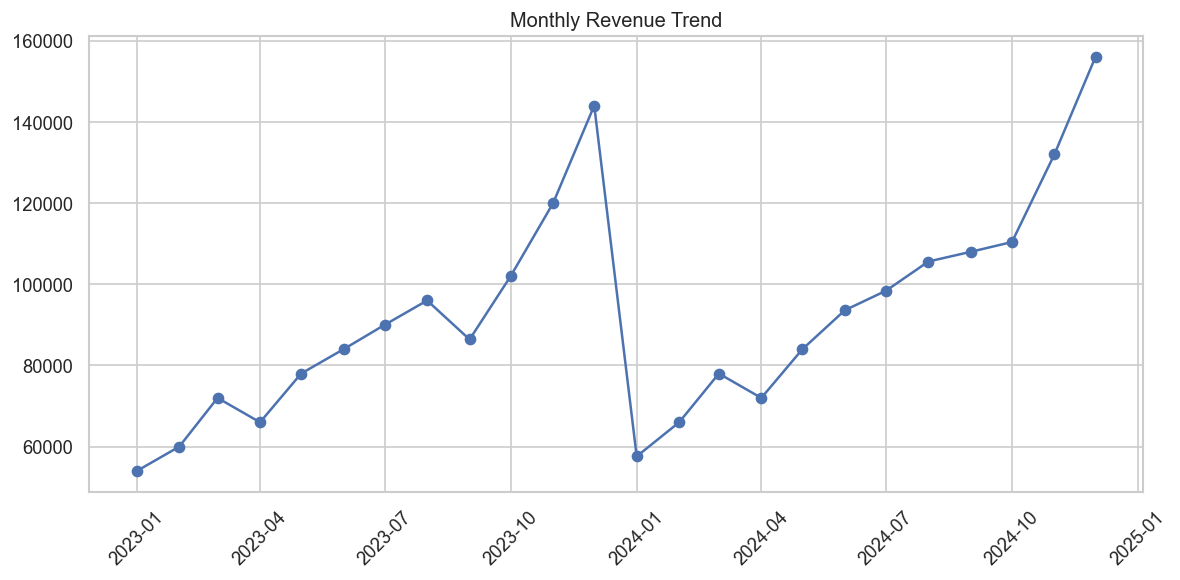


🔮 6-Month Forecast:
   MonthNum  Predicted_Revenue
0        25      121408.695652
1        26      123741.391304
2        27      126074.086957
3        28      128406.782609
4        29      130739.478261
5        30      133072.173913

🎉 DONE — no errors, no file needed


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid")

# ---- DATA: built directly in code, no CSV file needed ----
data = {
    "Date": pd.date_range(start="2023-01-01", periods=24, freq="MS"),
    "Revenue": [54000,60000,72000,66000,78000,84000,90000,96000,86400,102000,120000,144000,
                57600,66000,78000,72000,84000,93600,98400,105600,108000,110400,132000,156000],
    "AdSpend": [5000,5500,6000,5800,6500,7000,7500,8000,7200,8500,10000,12000,
                5200,5800,6500,6200,7000,7800,8200,8800,7500,9200,11000,13000]
}

df = pd.DataFrame(data)
df["Profit"] = df["Revenue"] - df["AdSpend"]
df["Month"] = df["Date"].dt.month
df["MonthNum"] = range(1, len(df) + 1)

print("✅ Data ready:", df.shape)
print(df.head())

# ---- CHART: Revenue trend ----
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["Date"], df["Revenue"], marker="o", color="#4C72B0")
ax.set_title("Monthly Revenue Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("chart1_revenue.png")
plt.show()

# ---- FORECAST ----
X = df[["MonthNum"]]
y = df["Revenue"]
model = LinearRegression()
model.fit(X, y)

future = pd.DataFrame({"MonthNum": range(25, 31)})
future["Predicted_Revenue"] = model.predict(future[["MonthNum"]])
print("\n🔮 6-Month Forecast:")
print(future)

print("\n🎉 DONE — no errors, no file needed")

✅ Data ready: (24, 6)
        Date  Revenue  AdSpend  Profit  Month  MonthNum
0 2023-01-01    54000     5000   49000      1         1
1 2023-02-01    60000     5500   54500      2         2
2 2023-03-01    72000     6000   66000      3         3
3 2023-04-01    66000     5800   60200      4         4
4 2023-05-01    78000     6500   71500      5         5


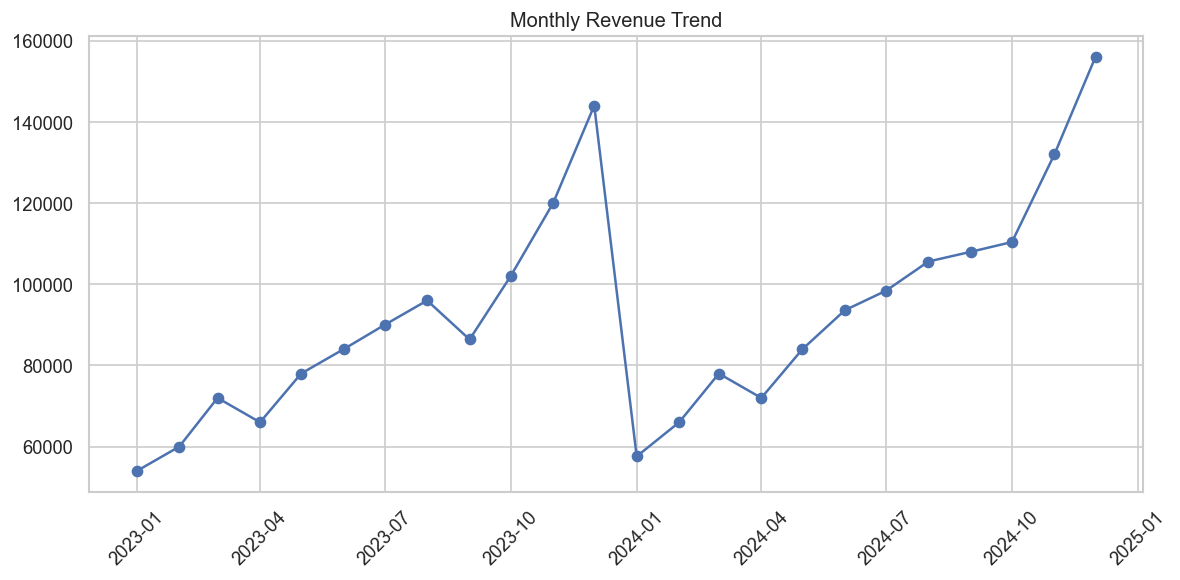


🔮 6-Month Forecast:
   MonthNum  Predicted_Revenue
0        25      121408.695652
1        26      123741.391304
2        27      126074.086957
3        28      128406.782609
4        29      130739.478261
5        30      133072.173913

🎉 DONE — no errors, no file needed


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid")

# ---- DATA: built directly in code, no CSV file needed ----
data = {
    "Date": pd.date_range(start="2023-01-01", periods=24, freq="MS"),
    "Revenue": [54000,60000,72000,66000,78000,84000,90000,96000,86400,102000,120000,144000,
                57600,66000,78000,72000,84000,93600,98400,105600,108000,110400,132000,156000],
    "AdSpend": [5000,5500,6000,5800,6500,7000,7500,8000,7200,8500,10000,12000,
                5200,5800,6500,6200,7000,7800,8200,8800,7500,9200,11000,13000]
}

df = pd.DataFrame(data)
df["Profit"] = df["Revenue"] - df["AdSpend"]
df["Month"] = df["Date"].dt.month
df["MonthNum"] = range(1, len(df) + 1)

print("✅ Data ready:", df.shape)
print(df.head())

# ---- CHART: Revenue trend ----
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["Date"], df["Revenue"], marker="o", color="#4C72B0")
ax.set_title("Monthly Revenue Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("chart1_revenue.png")
plt.show()

# ---- FORECAST ----
X = df[["MonthNum"]]
y = df["Revenue"]
model = LinearRegression()
model.fit(X, y)

future = pd.DataFrame({"MonthNum": range(25, 31)})
future["Predicted_Revenue"] = model.predict(future[["MonthNum"]])
print("\n🔮 6-Month Forecast:")
print(future)

print("\n🎉 DONE — no errors, no file needed")

  STEP 1: DATA READY

✅ Dataset built: 120 rows | 8 columns
        Date        Product     Category Region  UnitsSold  UnitPrice  \
0 2023-01-01     Laptop Pro  Electronics  North         44       1200   
1 2023-01-01    Smart Watch  Electronics  South         32        300   
2 2023-01-01   Office Chair    Furniture   East         20        450   
3 2023-01-01  Running Shoes      Fashion   West         61        120   
4 2023-01-01   Coffee Maker   Appliances  North         33         80   

   Revenue  AdSpend  
0    52800   4752.0  
1     9600    864.0  
2     9000    810.0  
3     7320    659.0  
4     2640    238.0  

✅ Month, Year, MonthNum, Profit columns added
💾 sales_clean.csv saved

  STEP 2: VISUALIZATION
✅ chart1_revenue_trend.png saved


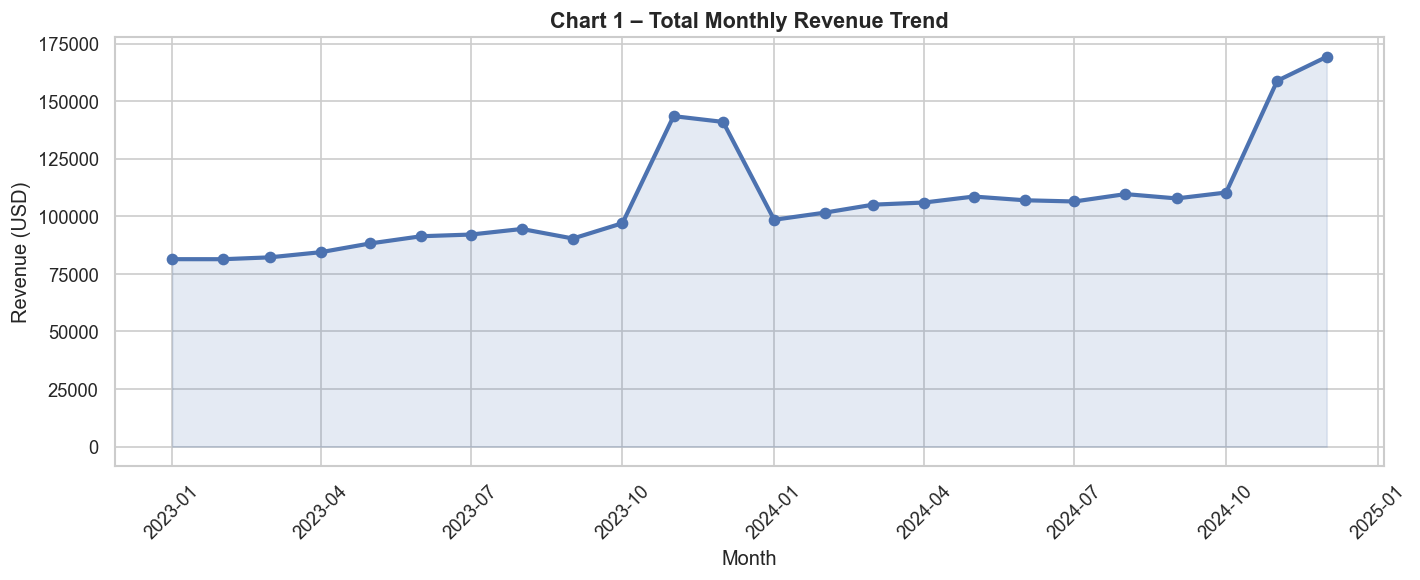

✅ chart2_revenue_by_product.png saved


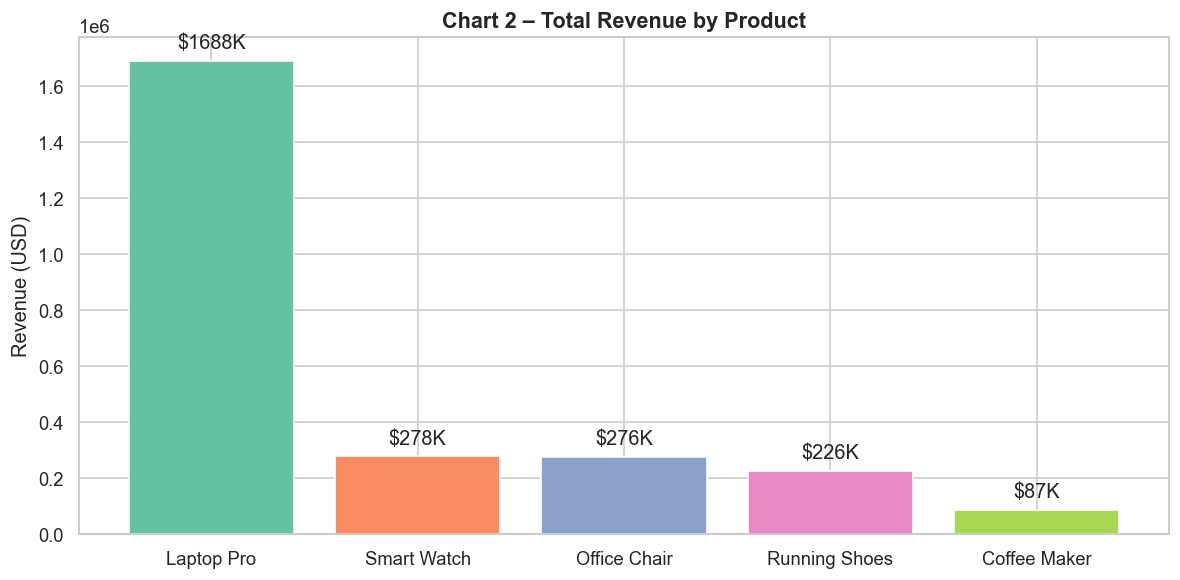

✅ chart3_category_region.png saved


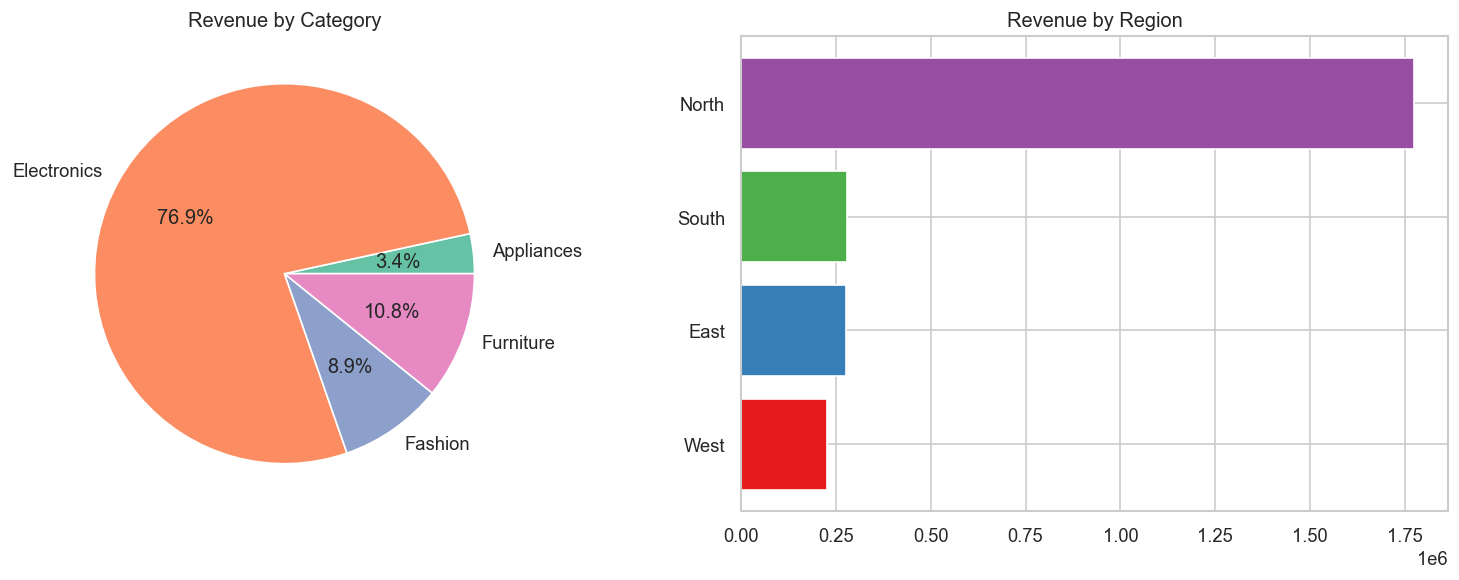

✅ chart4_adspend_vs_revenue.png saved


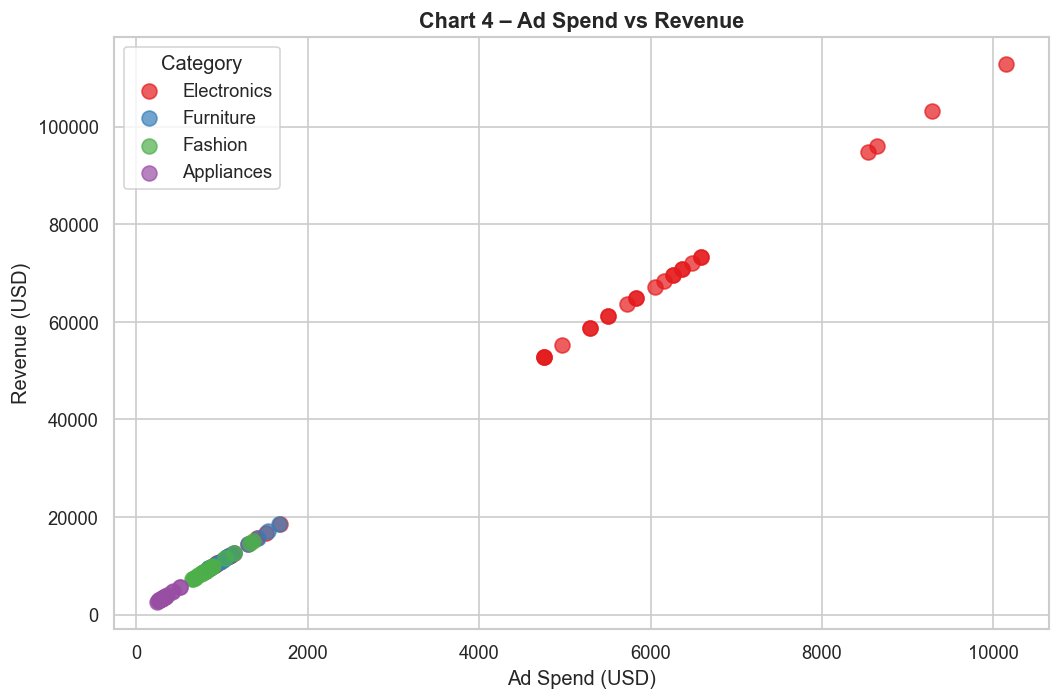

✅ chart5_monthly_profit.png saved


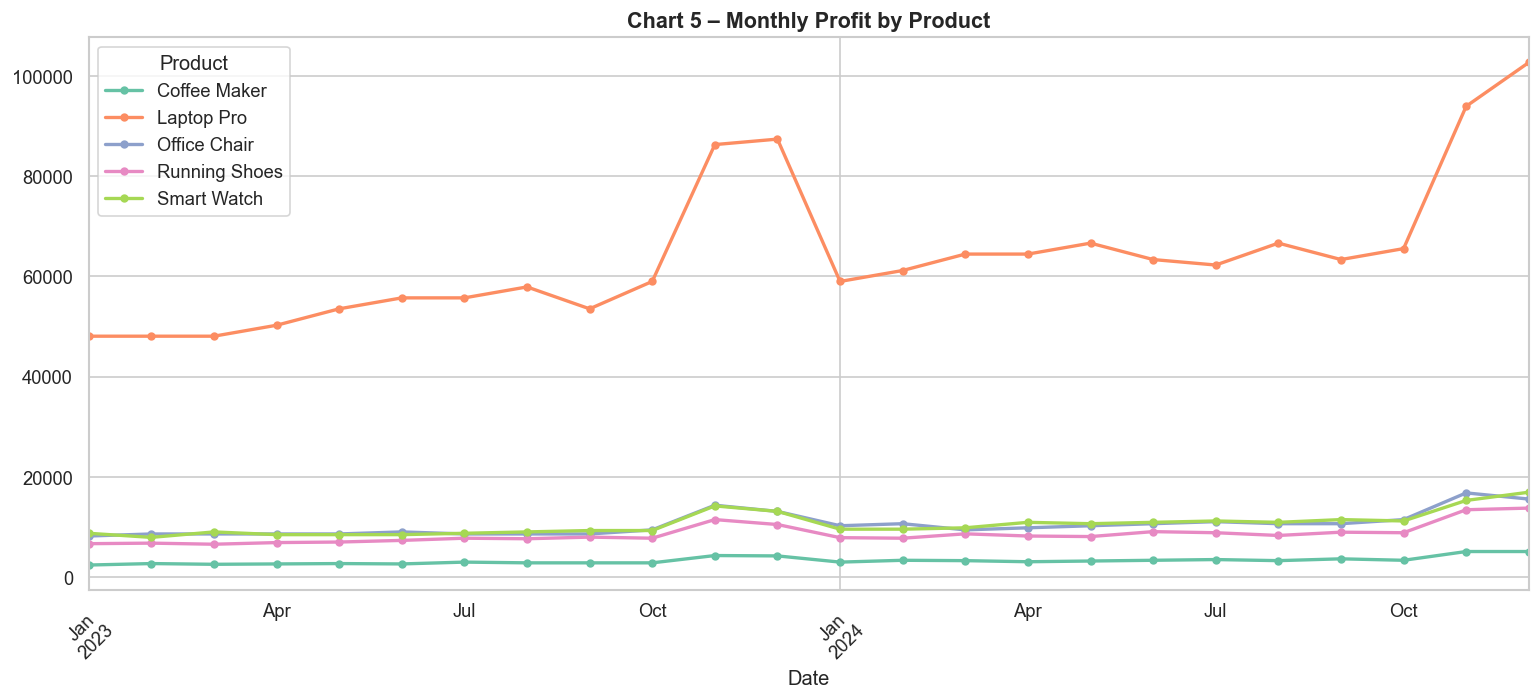

✅ chart6_heatmap.png saved


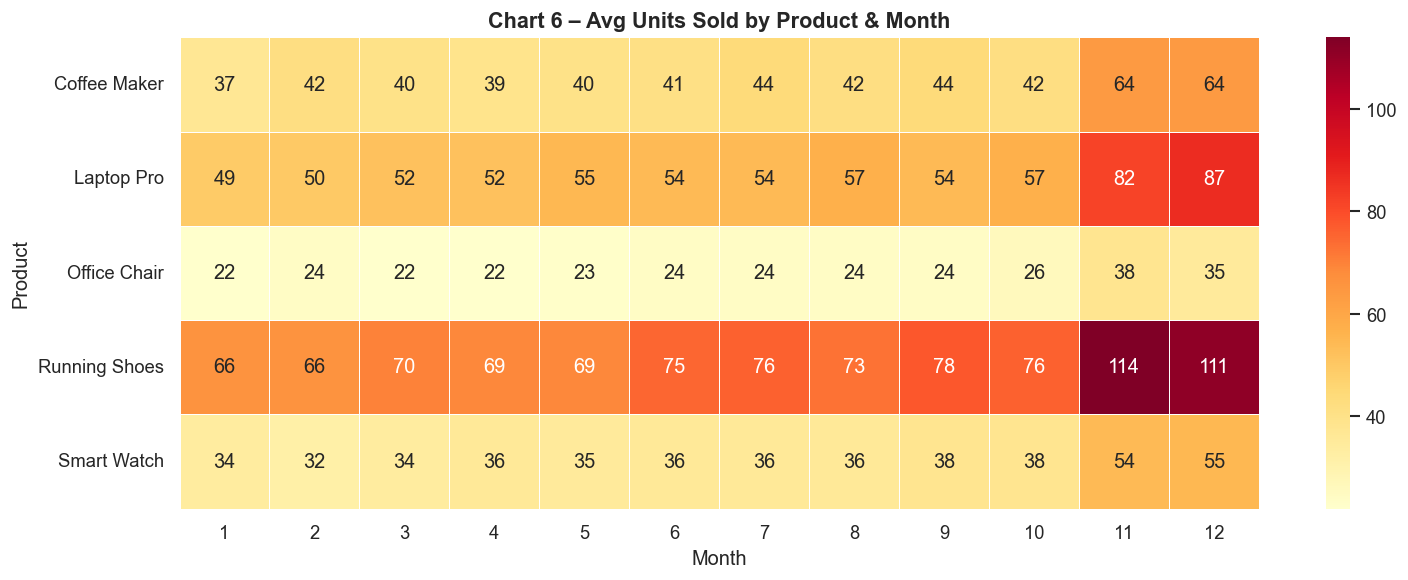


✅ STEP 2 COMPLETE - 6 charts saved

  STEP 3: SALES FORECASTING

📊 R² Score: 0.483   MAE: $11,796

🔮 6-Month Forecast:
  2025-01-01  →  $135,665
  2025-02-01  →  $138,000
  2025-03-01  →  $140,334
  2025-04-01  →  $142,668
  2025-05-01  →  $145,003
  2025-06-01  →  $147,337

✅ chart7_forecast.png saved


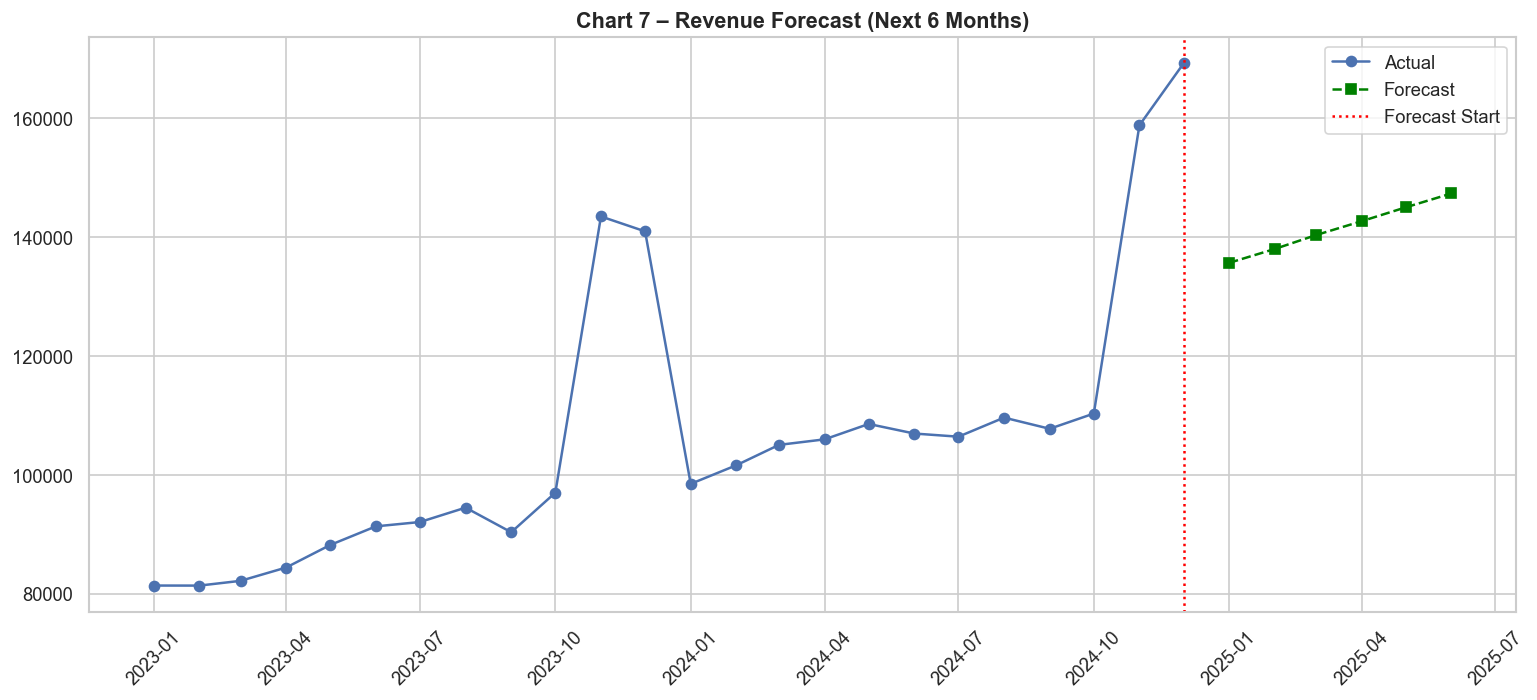

💾 sales_forecast.csv saved

🎉 PROJECT COMPLETE — all steps ran with zero file dependency!


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120

# ============================================================
#  DATA - built directly in code, no CSV file needed
# ============================================================
rows = []
products = {
    "Laptop Pro":    {"cat": "Electronics", "region": "North", "price": 1200},
    "Smart Watch":   {"cat": "Electronics", "region": "South", "price": 300},
    "Office Chair":  {"cat": "Furniture",   "region": "East",  "price": 450},
    "Running Shoes": {"cat": "Fashion",     "region": "West",  "price": 120},
    "Coffee Maker":  {"cat": "Appliances",  "region": "North", "price": 80},
}

units_base = {
    "Laptop Pro": 45, "Smart Watch": 30, "Office Chair": 20,
    "Running Shoes": 60, "Coffee Maker": 35
}

dates = pd.date_range(start="2023-01-01", periods=24, freq="MS")

np.random.seed(42)
for i, date in enumerate(dates):
    seasonal = 1.0 + (0.4 if date.month in [11, 12] else 0)  # holiday bump
    growth = 1 + (i * 0.018)
    for prod, info in products.items():
        units = int(units_base[prod] * growth * seasonal * np.random.uniform(0.95, 1.08))
        revenue = units * info["price"]
        adspend = round(revenue * 0.09, 0)
        rows.append({
            "Date": date, "Product": prod, "Category": info["cat"],
            "Region": info["region"], "UnitsSold": units,
            "UnitPrice": info["price"], "Revenue": revenue, "AdSpend": adspend
        })

df = pd.DataFrame(rows)
print("=" * 55)
print("  STEP 1: DATA READY")
print("=" * 55)
print(f"\n✅ Dataset built: {df.shape[0]} rows | {df.shape[1]} columns")
print(df.head())

# ============================================================
#  STEP 1b: FEATURE ENGINEERING
# ============================================================
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
df["MonthNum"] = (df["Year"] - df["Year"].min()) * 12 + df["Month"]
df["Profit"] = df["Revenue"] - df["AdSpend"]

print("\n✅ Month, Year, MonthNum, Profit columns added")
df.to_csv("sales_clean.csv", index=False)
print("💾 sales_clean.csv saved")

# ============================================================
#  STEP 2: VISUALIZATION
# ============================================================
print("\n" + "=" * 55)
print("  STEP 2: VISUALIZATION")
print("=" * 55)

# Chart 1 - Monthly revenue trend
monthly = df.groupby("Date")["Revenue"].sum().reset_index()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["Date"], monthly["Revenue"], marker="o", color="#4C72B0", linewidth=2.5)
ax.fill_between(monthly["Date"], monthly["Revenue"], alpha=0.15, color="#4C72B0")
ax.set_title("Chart 1 – Total Monthly Revenue Trend", fontsize=13, fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue (USD)")
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig("chart1_revenue_trend.png")
print("✅ chart1_revenue_trend.png saved")
plt.show()

# Chart 2 - Revenue by product
prod_rev = df.groupby("Product")["Revenue"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(prod_rev.index, prod_rev.values, color=sns.color_palette("Set2", len(prod_rev)))
ax.bar_label(bars, labels=[f"${v/1000:.0f}K" for v in prod_rev.values], padding=5)
ax.set_title("Chart 2 – Total Revenue by Product", fontsize=13, fontweight="bold")
ax.set_ylabel("Revenue (USD)")
plt.tight_layout()
plt.savefig("chart2_revenue_by_product.png")
print("✅ chart2_revenue_by_product.png saved")
plt.show()

# Chart 3 - Category pie + Region bar
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cat_rev = df.groupby("Category")["Revenue"].sum()
axes[0].pie(cat_rev, labels=cat_rev.index, autopct="%1.1f%%", colors=sns.color_palette("Set2"))
axes[0].set_title("Revenue by Category")
reg_rev = df.groupby("Region")["Revenue"].sum().sort_values()
axes[1].barh(reg_rev.index, reg_rev.values, color=sns.color_palette("Set1", len(reg_rev)))
axes[1].set_title("Revenue by Region")
plt.tight_layout()
plt.savefig("chart3_category_region.png")
print("✅ chart3_category_region.png saved")
plt.show()

# Chart 4 - AdSpend vs Revenue scatter
fig, ax = plt.subplots(figsize=(9, 6))
colors = sns.color_palette("Set1", df["Category"].nunique())
for i, cat in enumerate(df["Category"].unique()):
    mask = df["Category"] == cat
    ax.scatter(df.loc[mask, "AdSpend"], df.loc[mask, "Revenue"],
               label=cat, color=colors[i], s=80, alpha=0.7)
ax.set_title("Chart 4 – Ad Spend vs Revenue", fontsize=13, fontweight="bold")
ax.set_xlabel("Ad Spend (USD)"); ax.set_ylabel("Revenue (USD)")
ax.legend(title="Category")
plt.tight_layout()
plt.savefig("chart4_adspend_vs_revenue.png")
print("✅ chart4_adspend_vs_revenue.png saved")
plt.show()

# Chart 5 - Monthly profit by product
monthly_profit = df.groupby(["Date", "Product"])["Profit"].sum().unstack()
fig, ax = plt.subplots(figsize=(13, 6))
monthly_profit.plot(ax=ax, linewidth=2, marker="o", markersize=4)
ax.set_title("Chart 5 – Monthly Profit by Product", fontsize=13, fontweight="bold")
ax.legend(title="Product", loc="upper left")
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig("chart5_monthly_profit.png")
print("✅ chart5_monthly_profit.png saved")
plt.show()

# Chart 6 - Heatmap units sold by product/month
pivot = df.pivot_table(values="UnitsSold", index="Product", columns="Month", aggfunc="mean").round(0)
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5, ax=ax)
ax.set_title("Chart 6 – Avg Units Sold by Product & Month", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("chart6_heatmap.png")
print("✅ chart6_heatmap.png saved")
plt.show()

print("\n✅ STEP 2 COMPLETE - 6 charts saved")

# ============================================================
#  STEP 3: FORECASTING
# ============================================================
print("\n" + "=" * 55)
print("  STEP 3: SALES FORECASTING")
print("=" * 55)

monthly_total = df.groupby(["MonthNum", "Date"])["Revenue"].sum().reset_index().sort_values("MonthNum")
X = monthly_total[["MonthNum"]]
y = monthly_total["Revenue"]

model = LinearRegression()
model.fit(X, y)
monthly_total["Predicted"] = model.predict(X)

r2 = r2_score(y, monthly_total["Predicted"])
mae = mean_absolute_error(y, monthly_total["Predicted"])
print(f"\n📊 R² Score: {r2:.3f}   MAE: ${mae:,.0f}")

last_month = monthly_total["MonthNum"].max()
future = pd.DataFrame({"MonthNum": range(last_month + 1, last_month + 7)})
future["Predicted_Revenue"] = model.predict(future[["MonthNum"]])
last_date = monthly_total["Date"].max()
future["Date"] = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=6, freq="MS")

print("\n🔮 6-Month Forecast:")
for _, row in future.iterrows():
    print(f"  {row['Date'].date()}  →  ${row['Predicted_Revenue']:,.0f}")

# Forecast chart
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(monthly_total["Date"], monthly_total["Revenue"], label="Actual", color="#4C72B0", marker="o")
ax.plot(future["Date"], future["Predicted_Revenue"], label="Forecast", color="green",
        linestyle="--", marker="s")
ax.axvline(x=last_date, color="red", linestyle=":", label="Forecast Start")
ax.set_title("Chart 7 – Revenue Forecast (Next 6 Months)", fontsize=13, fontweight="bold")
ax.legend()
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig("chart7_forecast.png")
print("\n✅ chart7_forecast.png saved")
plt.show()

future[["Date", "Predicted_Revenue"]].to_csv("sales_forecast.csv", index=False)
print("💾 sales_forecast.csv saved")

print("\n🎉 PROJECT COMPLETE — all steps ran with zero file dependency!")
